### Datan lataus Iän kuvailu ja Boxplot

In [100]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import scipy.stats as stats

df = pd.read_excel('WorkPlaceSatisfactionSurveyData.xlsx', sheet_name='Data')

In [101]:
df.head()

,number,gender,age,family,education,years_of_service,salary,sat_management,sat_colleques,sat_workingEnvironment,sat_salary,sat_tasks,holidayCabin,gym,muscleCare,healtcare
0,1,1,38,1,1.0,22.0,3587,3,3.0,3,3,3,NaN,NaN,NaN,NaN
1,2,1,29,2,2.0,10.0,2963,1,5.0,2,1,3,NaN,NaN,NaN,NaN
2,3,1,30,1,1.0,7.0,1989,3,4.0,1,1,3,NaN,NaN,NaN,1.0
3,4,1,36,2,1.0,14.0,2144,3,3.0,3,3,3,NaN,NaN,NaN,1.0
4,5,1,24,1,2.0,4.0,2183,2,3.0,2,1,2,NaN,NaN,NaN,1.0


In [102]:
df.columns

Index(['number', 'gender', 'age', 'family', 'education', 'years_of_service',
       'salary', 'sat_management', 'sat_colleques', 'sat_workingEnvironment',
       'sat_salary', 'sat_tasks', 'holidayCabin', 'gym', 'muscleCare',
       'healtcare'],
      dtype='object')

## Poistetaan turhat sarakkeet joiden arvo on NaN

In [103]:
df= df.drop(columns=['holidayCabin', 'gym', 'muscleCare', 'healtcare'])
df.head(1)

,number,gender,age,family,education,years_of_service,salary,sat_management,sat_colleques,sat_workingEnvironment,sat_salary,sat_tasks
0,1,1,38,1,1.0,22.0,3587,3,3.0,3,3,3


## poistetaan sarakkeet joita en käytä analyysissäni

In [104]:


df = df.drop(columns=['number', 'education', 'salary', 'family', 'years_of_service'])
df.head()



,gender,age,sat_management,sat_colleques,sat_workingEnvironment,sat_salary,sat_tasks
0,1,38,3,3.0,3,3,3
1,1,29,1,5.0,2,1,3
2,1,30,3,4.0,1,1,3
3,1,36,3,3.0,3,3,3
4,1,24,2,3.0,2,1,2


## nimetään ne uusiksi

In [105]:
df2 = df
df2.columns = ['sukupuoli', 'ikä', 'sat_johto', 'sat_kolleegat','sat_tyoymparisto','sat_palkka','sat_tyotehtavat']
df2.head()

,sukupuoli,ikä,sat_johto,sat_kolleegat,sat_tyoymparisto,sat_palkka,sat_tyotehtavat
0,1,38,3,3.0,3,3,3
1,1,29,1,5.0,2,1,3
2,1,30,3,4.0,1,1,3
3,1,36,3,3.0,3,3,3
4,1,24,2,3.0,2,1,2


In [106]:
print (df['ikä'].describe())

count    82.000000
mean     37.951220
std       9.773866
min      20.000000
25%      31.000000
50%      37.500000
75%      44.000000
max      61.000000
Name: ikä, dtype: float64


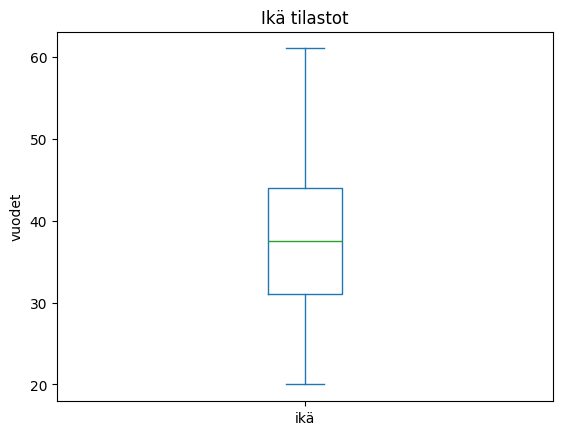

In [107]:
df['ikä'].plot.box()
plt.title('Ikä tilastot')
plt.ylabel('vuodet')
plt.show()

### Sukupuolen analyysi ja Iän luokittelu

In [108]:
sukupuoli_kpl = df['sukupuoli'].value_counts()
sukupuoli_pros = df['sukupuoli'].value_counts(normalize=True) * 100

print("sukupuoli kpl:")
print(sukupuoli_kpl)
print("sukupuoli_prosentteina")
print(sukupuoli_pros)

sukupuoli kpl:
sukupuoli
1    63
2    19
Name: count, dtype: int64
sukupuoli_prosentteina
sukupuoli
1    76.829268
2    23.170732
Name: proportion, dtype: float64


<function matplotlib.pyplot.show(close=None, block=None)>

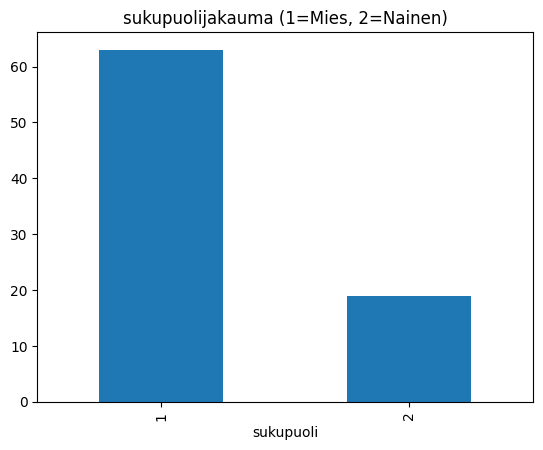

In [109]:
sukupuoli_kpl.plot(kind='bar')
plt.title ('sukupuolijakauma (1=Mies, 2=Nainen)')
plt.show

In [110]:
df['ikäryhmä'] = ['Alle 40' if ikä < 40 else '40 tai yli' for ikä in df ['ikä']]

ikäryhmä_kpl = df['ikäryhmä'].value_counts()
print("ikä count:")
print(ikäryhmä_kpl)

ikä count:
ikäryhmä
Alle 40       47
40 tai yli    35
Name: count, dtype: int64


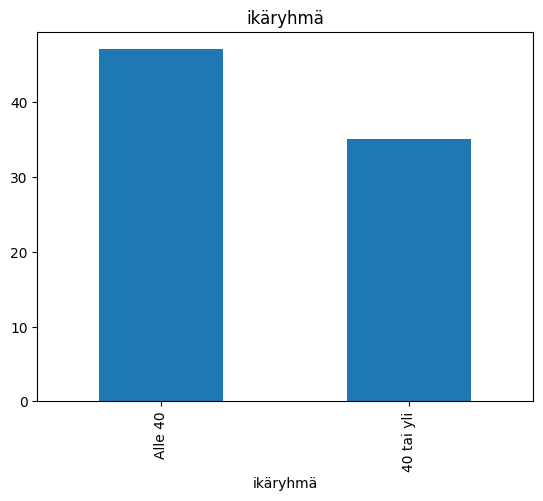

In [111]:
ikäryhmä_kpl.plot(kind='bar')
plt.title('ikäryhmä')
plt.show()

### Kahden muuttujan analyysit

In [112]:
taulukko_sukupuoli = pd.crosstab(df['sukupuoli'], df['sat_palkka'])
print("Sukupuoli ja palkkatyytyväisyys:")
print(taulukko_sukupuoli)

Sukupuoli ja palkkatyytyväisyys:
sat_palkka   1   2   3  4  5
sukupuoli                   
1           32  12  12  7  0
2            1   7   7  3  1


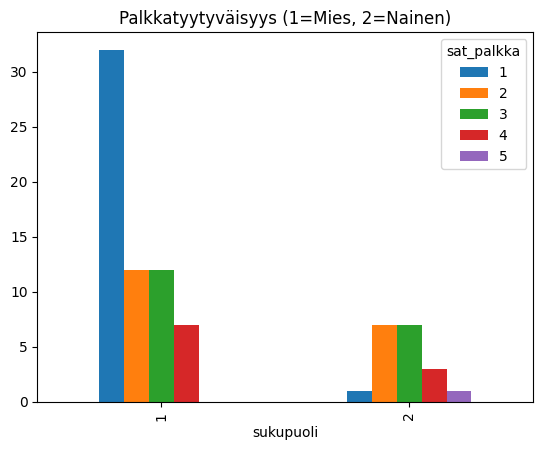

In [113]:
taulukko_sukupuoli.plot(kind='bar')
plt.title('Palkkatyytyväisyys (1=Mies, 2=Nainen)')
plt.show()

In [114]:
taulukko_ikä = pd.crosstab(df['ikäryhmä'], df['sat_johto'])
print("Ikäryhmä ja tyytyväisyys johtoon:")
print(taulukko_ikä)

Ikäryhmä ja tyytyväisyys johtoon:
sat_johto   1  2   3   4  5
ikäryhmä                   
40 tai yli  2  8  11  10  4
Alle 40     5  8  19  13  2


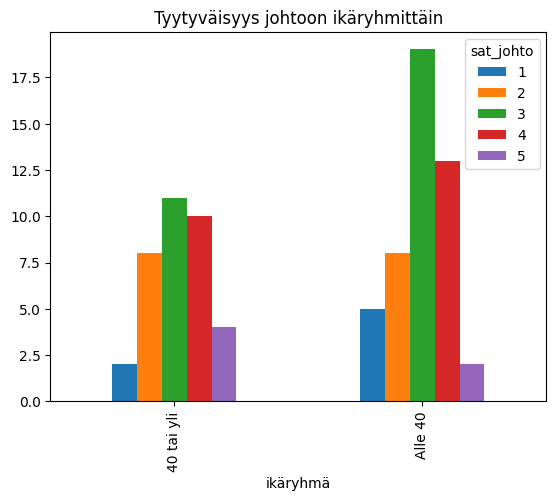

In [115]:
taulukko_ikä.plot(kind='bar')
plt.title('Tyytyväisyys johtoon ikäryhmittäin')
plt.show()

In [116]:
chi2, p_arvo_chi, dof, ex = stats.chi2_contingency(taulukko_ikä)
print("Chi2 testin p-arvo (Ikäryhmä vs Johto):", p_arvo_chi)

keskiarvot = df.groupby('sukupuoli')['sat_palkka'].mean()
print("Palkkatyytyväisyyden keskiarvot sukupuolittain:")
print(keskiarvot)

Chi2 testin p-arvo (Ikäryhmä vs Johto): 0.5952091282294939
Palkkatyytyväisyyden keskiarvot sukupuolittain:
sukupuoli
1    1.904762
2    2.789474
Name: sat_palkka, dtype: float64


In [117]:
miehet = df[df['sukupuoli'] == 1]['sat_palkka'].dropna()
naiset = df[df['sukupuoli'] == 2]['sat_palkka'].dropna()

t_arvo, p_arvo_t = stats.ttest_ind(miehet, naiset)
print("T-testin p-arvo (Palkkaero sukupuolittain):", p_arvo_t)

T-testin p-arvo (Palkkaero sukupuolittain): 0.0018984804754973905
